In [1]:
import numpy
import seaborn

from realistic import load_realistic_lombscargle, load_realistic_timeseries
from pristine import load_pristine_lombscargle, load_pristine_timeseries

In [2]:
porb_limit = 365
ts_cols = ['a', 'e', 'periapsis_phase', 'Macc']

In [3]:
pts = load_pristine_timeseries()
rts = load_realistic_timeseries()
pls = load_pristine_lombscargle().merge(pts[ts_cols], how='left', left_on='pristine_idx', right_index=True)
rls = load_realistic_lombscargle().merge(rts[ts_cols + ['cadence', 'RV accuracy']], how='left', left_on='pristine_idx', right_index=True)

In [4]:
rls = rls[rls['Porb'] <= porb_limit]
pls = pls[pls['Porb'] <= porb_limit]

In [5]:
pls['pristine close'] = numpy.isclose(pls['top_period'], pls['Porb'], rtol=0.1)
rls['realistic close'] = numpy.isclose(rls['top_period'], rls['Porb'], rtol=0.1)

In [6]:
pls

,pristine_idx,top_period,Porb,a,e,periapsis_phase,Macc,pristine close
0,0,11.030303,11.012910,0.100000,0.0,0.000000,0.100000,True
1,1,4.918919,4.915203,0.100000,0.0,0.000000,4.522222,True
2,2,4.155251,4.153508,0.100000,0.0,0.000000,6.733333,True
3,3,6.341463,6.347629,0.100000,0.0,0.000000,2.311111,True
4,4,3.315118,3.312921,0.100000,0.0,0.000000,11.155556,True
...,...,...,...,...,...,...,...,...
5041,5041,364.000000,360.145546,2.277778,0.9,6.283185,11.155556,True
5043,5043,303.333333,274.003309,2.277778,0.9,6.283185,20.000000,False
5046,5046,303.333333,308.391428,2.277778,0.9,6.283185,15.577778,True
5047,5047,303.333333,289.677594,2.277778,0.9,5.585054,17.788889,True


In [7]:
counts = rls.merge(pls[['pristine_idx', 'pristine close']], on='pristine_idx')[['realistic close', 'pristine close']].value_counts()
counts


realistic close  pristine close
False            True              23885600
True             True               3013600
False            False               262320
True             False                   80
Name: count, dtype: int64

# Pristine

<Axes: xlabel='Porb', ylabel='Count'>

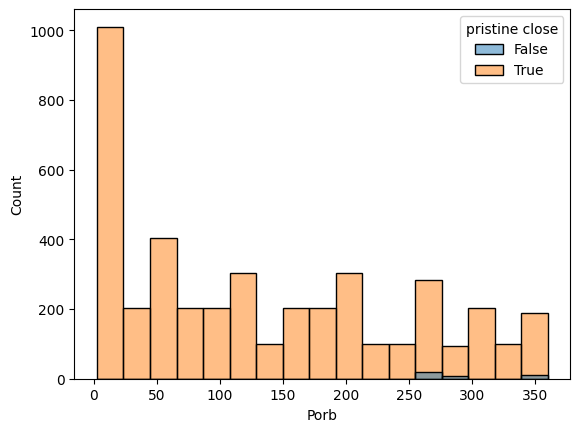

In [8]:
seaborn.histplot(pls, x="Porb", hue='pristine close')

# Realistic

<Axes: xlabel='Porb', ylabel='Count'>

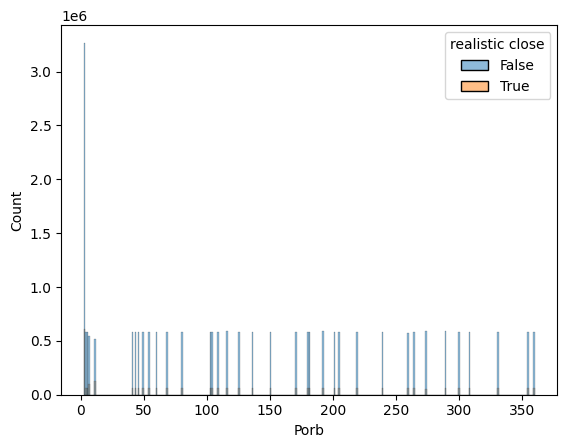

In [10]:
seaborn.histplot(rls, x="Porb", hue='realistic close')

<Axes: xlabel='cadence', ylabel='Count'>

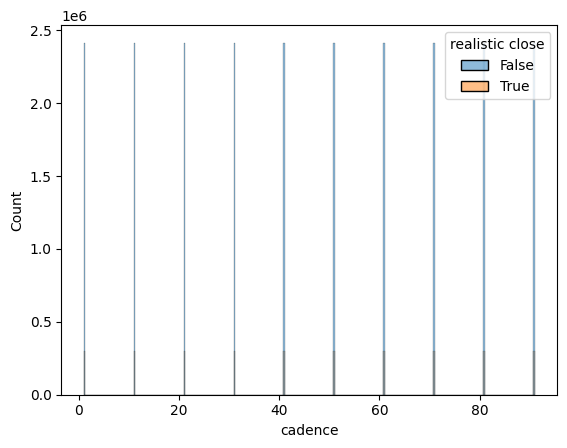

In [14]:
seaborn.histplot(rls, x="cadence", hue='realistic close')

<Axes: xlabel='RV accuracy', ylabel='Count'>

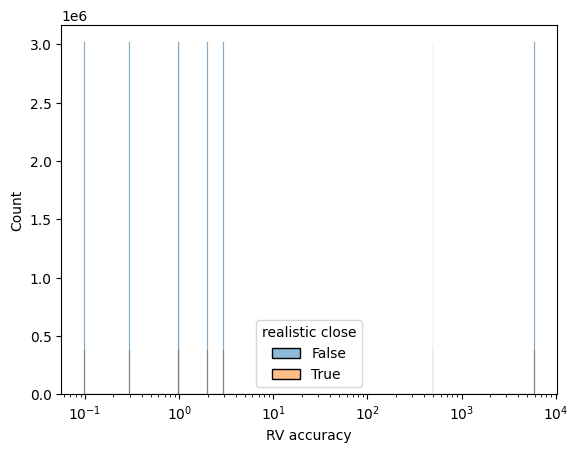

In [16]:
seaborn.histplot(rls, x="RV accuracy", hue='realistic close', log_scale=True)

<Axes: xlabel='cadence', ylabel='Porb'>

/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


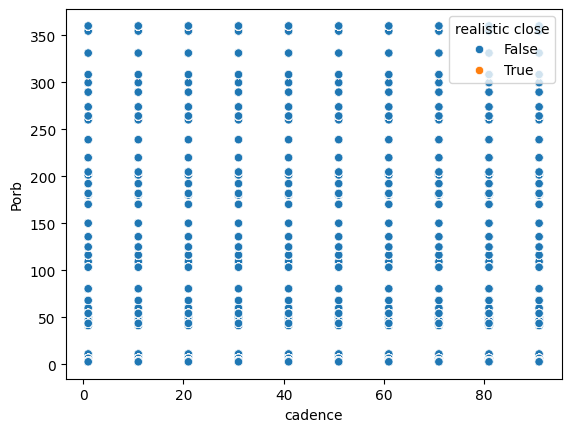

In [12]:
seaborn.scatterplot(rls, y='Porb', x='cadence', hue='realistic close')

<Axes: xlabel='cadence', ylabel='Porb'>

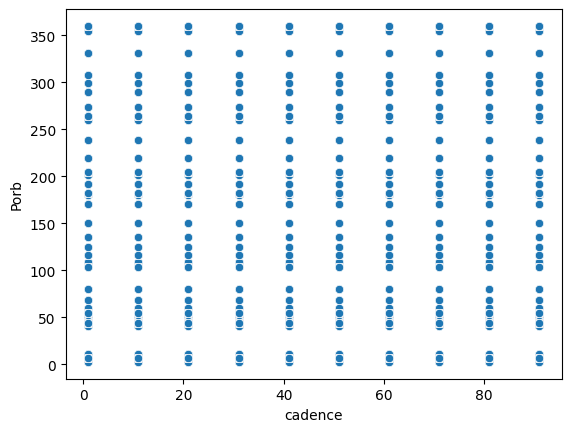

In [17]:
seaborn.scatterplot(rls[rls['realistic close']], y='Porb', x='cadence')

<Axes: xlabel='cadence', ylabel='RV accuracy'>

/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


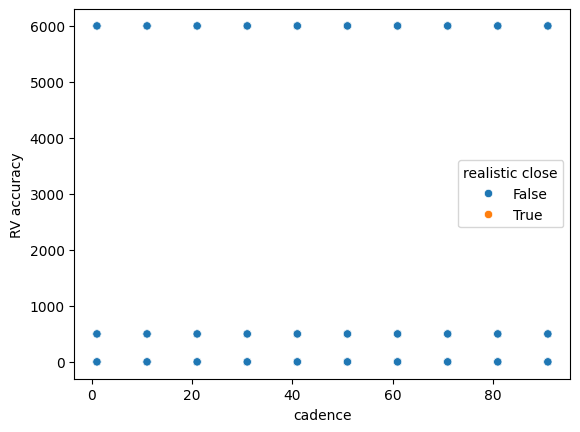

In [13]:
seaborn.scatterplot(rls, y='RV accuracy', x='cadence', hue='realistic close')

<Axes: xlabel='cadence', ylabel='RV accuracy'>

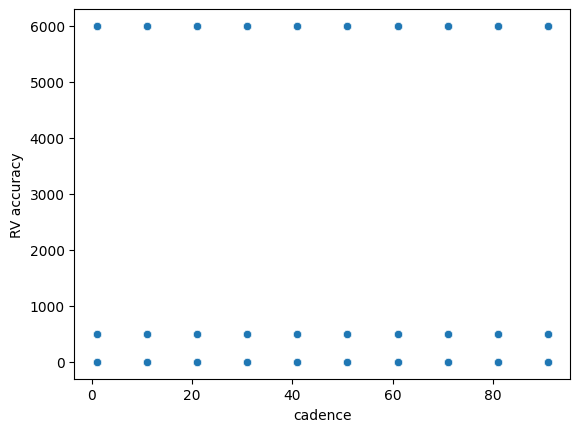

In [18]:
seaborn.scatterplot(rls[rls['realistic close']], y='RV accuracy', x='cadence')